LOADING IN THE DATA + LIBRARIES

In [ ]:
import pandas as pd
import numpy as np
import os

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Clones repo into collab files
# Run only once per runtime
!git clone https://github.com/Break-Through-Tech/Microsoft-4A-groundwater-timeseries-prediction-using-AI

Cloning into 'Microsoft-4A-groundwater-timeseries-prediction-using-AI'...
remote: Enumerating objects: 106, done.
remote: Counting objects: 100% (106/106), done.
remote: Compressing objects: 100% (96/96), done.
remote: Total 106 (delta 54), reused 9 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (106/106), 9.71 MiB | 2.89 MiB/s, done.
Resolving deltas: 100% (54/54), done.
Updating files: 100% (10/10), done.


In [ ]:
monthly_filename = os.path.join(
    "/content", "Microsoft-4A-groundwater-timeseries-prediction-using-AI", "data", "nld_regional_105_wells_2012_2022.csv"
)
daily_filename = os.path.join(
    "/content", "Microsoft-4A-groundwater-timeseries-prediction-using-AI", "data", "svn_regional_53_wells_daily_2019_2023.csv"
)

df_monthly = pd.read_csv(monthly_filename, header=0)
df_daily = pd.read_csv(daily_filename, header=0)

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

/tmp/ipykernel_517/168685579.py:9: DtypeWarning: Columns (58) have mixed types. Specify dtype option on import or set low_memory=False.
  df_daily = pd.read_csv(daily_filename, header=0)


DATA PROPROCESSING (DAILY)

In [ ]:
# We will work with the daily dataset for the first part of our project because it has much more information.

print("Monthly Dataset Shape")
display(df_monthly.shape)
print("Daily Dataset Shape")
display(df_daily.shape)

Monthly Dataset Shape


(13860, 64)

Daily Dataset Shape


(96778, 65)

In [ ]:
# Let's start by skimming over our data, starting with the columns.
for col in df_daily.columns:
    print(col)

GROW_ID
interval
date
year
month
aggregated_from_n_values
outliers_change_points
plateaus
groundwater_water_level_elevation_m_asl
precipitation_mswep_mm_year-1
precipitation_gpcc_mm_year-1
potential_evapotranspiration_era5_mm_year-1
potential_evapotranspiration_gleam_mm_year-1
actual_evapotranspiration_mm_year-1
interception_mm_year-1
air_temperature_°C
snow_depth_m
days_with_snow_cover_days_year-1
ndvi_ratio
lai_low_vegetation_ratio
lai_high_vegetation_ratio
withdrawal_industrial_m3_year-1
withdrawal_domestic_m3_year-1
urban_area_fraction
pastures_fraction
cropland_rainfed_fraction
cropland_irrigated_fraction
forests_natural_vegetation_fraction
original_ID_groundwater
name
feature_type
purpose
status
latitude
longitude
country
aquifer_name
confinement
organisation
license
starting_date
ending_date
length_years
autocorrelation
gap_fraction
trend_direction
trend_slope_m_year-1
reference_point
groundwater_mean_m
groundwater_median_m
koeppen_geiger_class
hydrobelt_class
ground_elevation_m

In [ ]:
# Take a preview at our dataset to see if anything stands out.

print("Daily Dataset Preview")
display(df_daily.head())

Daily Dataset Preview


,GROW_ID,interval,date,year,month,aggregated_from_n_values,outliers_change_points,plateaus,groundwater_water_level_elevation_m_asl,precipitation_mswep_mm_year-1,precipitation_gpcc_mm_year-1,potential_evapotranspiration_era5_mm_year-1,potential_evapotranspiration_gleam_mm_year-1,actual_evapotranspiration_mm_year-1,interception_mm_year-1,air_temperature_°C,snow_depth_m,days_with_snow_cover_days_year-1,ndvi_ratio,lai_low_vegetation_ratio,lai_high_vegetation_ratio,withdrawal_industrial_m3_year-1,withdrawal_domestic_m3_year-1,urban_area_fraction,pastures_fraction,cropland_rainfed_fraction,cropland_irrigated_fraction,forests_natural_vegetation_fraction,original_ID_groundwater,name,feature_type,purpose,status,latitude,longitude,country,aquifer_name,confinement,organisation,license,starting_date,ending_date,length_years,autocorrelation,gap_fraction,trend_direction,trend_slope_m_year-1,reference_point,groundwater_mean_m,groundwater_median_m,koeppen_geiger_class,hydrobelt_class,ground_elevation_merit_m_asl,topographic_slope_degree,aquifer_type_class,permeability_0-100_m_m-2,total_porosity_0-100_m_fraction,soil_texture_0-30_cm_class,soil_texture_30-200_cm_class,soil_saturated_conductivity_0-30_cm_cm_d-1,soil_saturated_conductivity_30-200_cm_cm_d-1,distance_perennial_streams_m,drainage_density_m-1,main_landuse_class,distance_to_cluster_center_km
0,GROW-18108201772,d,2019-01-01,2019,2019-01,NaN,False,0,304.83,45.625,821.04,109.837026,98.319356,87.170150,28.274261,1.86523,0.007568,82.0,0.3128,2.940338,1.082947,81079016.0,17460536.0,0.028556,0.09373,0.051826,0.0,0.825888,1173,Mengeš (Mp-0275),Water well,Observation / monitoring,NaN,46.180855,14.581305,SVN,NaN,NaN,"Slovenia - MINISTRY OF THE ENVIRONMENT, CLIMATE AND ENERGY",Attribution 4.0 International (CC BY 4.0),2004-01-01,2023-12-31,20,True,0.000137,decreasing,-0.109268,Water level elevation a.m.s.l.,305.884637,305.38,Cfb,Mid-latitude,332.2,0.75,karst,3.019952e-11,0.22,Fine,Medium,5.8697,3.4658,4100.0,0.00031,forests_and_natural_vegetation,17.231858
1,GROW-18108201772,d,2019-01-02,2019,2019-01,NaN,False,0,304.79,0.000,821.04,224.211817,102.139899,89.009648,0.000000,0.65912,0.007812,82.0,0.1503,2.940125,1.078125,81079016.0,17460536.0,0.028556,0.09373,0.051826,0.0,0.825888,1173,Mengeš (Mp-0275),Water well,Observation / monitoring,NaN,46.180855,14.581305,SVN,NaN,NaN,"Slovenia - MINISTRY OF THE ENVIRONMENT, CLIMATE AND ENERGY",Attribution 4.0 International (CC BY 4.0),2004-01-01,2023-12-31,20,True,0.000137,decreasing,-0.109268,Water level elevation a.m.s.l.,305.884637,305.38,Cfb,Mid-latitude,332.2,0.75,karst,3.019952e-11,0.22,Fine,Medium,5.8697,3.4658,4100.0,0.00031,forests_and_natural_vegetation,17.231858
2,GROW-18108201772,d,2019-01-03,2019,2019-01,NaN,False,0,304.73,0.000,821.04,437.022274,580.862387,454.509862,0.000000,-0.86993,0.007324,82.0,0.4445,2.939972,1.073334,81079016.0,17460536.0,0.028556,0.09373,0.051826,0.0,0.825888,1173,Mengeš (Mp-0275),Water well,Observation / monitoring,NaN,46.180855,14.581305,SVN,NaN,NaN,"Slovenia - MINISTRY OF THE ENVIRONMENT, CLIMATE AND ENERGY",Attribution 4.0 International (CC BY 4.0),2004-01-01,2023-12-31,20,True,0.000137,decreasing,-0.109268,Water level elevation a.m.s.l.,305.884637,305.38,Cfb,Mid-latitude,332.2,0.75,karst,3.019952e-11,0.22,Fine,Medium,5.8697,3.4658,4100.0,0.00031,forests_and_natural_vegetation,17.231858
3,GROW-18108201772,d,2019-01-04,2019,2019-01,NaN,False,0,304.68,0.000,821.04,370.233991,523.731382,416.227750,0.000000,-1.03696,0.008057,82.0,0.4081,2.939758,1.068573,81079016.0,17460536.0,0.028556,0.09373,0.051826,0.0,0.825888,1173,Mengeš (Mp-0275),Water well,Observation / monitoring,NaN,46.180855,14.581305,SVN,NaN,NaN,"Slovenia - MINISTRY OF THE ENVIRONMENT, CLIMATE AND ENERGY",Attribution 4.0 International (CC BY 4.0),2004-01-01,2023-12-31,20,True,0.000137,decreasing,-0.109268,Water level elevation a.m.s.l.,305.884637,305.38,Cfb,Mid-latitude,332.2,0.75,karst,3.019952e-11,0.22,Fine,Medium,5.8697,3.4658,4100.0,0.00031,forests_and_natu

In [ ]:
# There a few columns that potentially stand out. For instance, GROW_ID is likely an identifier for our data and might have nothing to do with the actual findings.
# There are also columns that seem to consist of mostly missing values, such as aggregated_from_n_values. Other columns seem to have one dominant value that most rows have.

# Let's first discuss missing values.

summary = pd.DataFrame({
    "nan_count": df_daily.isna().sum(),
    "nan_pct": (df_daily.isna().mean() * 100).round(2),
})
print(summary.sort_values("nan_pct", ascending=False))

                                              nan_count  nan_pct
aggregated_from_n_values                          96778   100.00
confinement                                       96778   100.00
status                                            96778   100.00
aquifer_name                                      96778   100.00
precipitation_gpcc_mm_year-1                      58035    59.97
trend_slope_m_year-1                              49302    50.94
withdrawal_industrial_m3_year-1                   38690    39.98
urban_area_fraction                               38690    39.98
forests_natural_vegetation_fraction               38690    39.98
withdrawal_domestic_m3_year-1                     38690    39.98
cropland_rainfed_fraction                         38690    39.98
pastures_fraction                                 38690    39.98
cropland_irrigated_fraction                       38690    39.98
soil_texture_30-200_cm_class                      21912    22.64
ndvi_ratio               

In [ ]:
# There are a few takeaways from the data above.
# First there are four columns that are missing for all rows in our data. These columns can be dropped with no issue.

missing_cols = summary.index[summary["nan_pct"] == 100].tolist()
df_daily.drop(columns=missing_cols, inplace=True)

summary = pd.DataFrame({
    "nan_count": df_daily.isna().sum(),
    "nan_pct": (df_daily.isna().mean() * 100).round(2),
})
print(summary.sort_values("nan_pct", ascending=False))

                                              nan_count  nan_pct
precipitation_gpcc_mm_year-1                      58035    59.97
trend_slope_m_year-1                              49302    50.94
cropland_irrigated_fraction                       38690    39.98
pastures_fraction                                 38690    39.98
forests_natural_vegetation_fraction               38690    39.98
withdrawal_domestic_m3_year-1                     38690    39.98
urban_area_fraction                               38690    39.98
cropland_rainfed_fraction                         38690    39.98
withdrawal_industrial_m3_year-1                   38690    39.98
soil_texture_30-200_cm_class                      21912    22.64
ndvi_ratio                                         1114     1.15
groundwater_water_level_elevation_m_asl               5     0.01
date                                                  0     0.00
actual_evapotranspiration_mm_year-1                   0     0.00
potential_evapotranspirat

In [ ]:
# Now, we turn our focus to columns that have some missing data.

# Find the data type for columns with some missing data
missingish_cols = summary.index[summary["nan_pct"] > 0].tolist()
for col in missingish_cols:
  print(f"{col}: {df_daily[col].dtype}")

groundwater_water_level_elevation_m_asl: float64
precipitation_gpcc_mm_year-1: float64
ndvi_ratio: float64
withdrawal_industrial_m3_year-1: float64
withdrawal_domestic_m3_year-1: float64
urban_area_fraction: float64
pastures_fraction: float64
cropland_rainfed_fraction: float64
cropland_irrigated_fraction: float64
forests_natural_vegetation_fraction: float64
trend_slope_m_year-1: float64
soil_texture_30-200_cm_class: object


In [ ]:
# Most of these columns consist of values with the datatype float.
# These columns can thus be handled in a variety of ways, particularly interpolation since our data is order according to date.

# To gain the most information possible, check if these columns are largely unique and nonzero in nature
df_m = df_daily[list(set(missingish_cols) - {"soil_texture_30-200_cm_class"})]
n_valid = df_m.notna().sum()          # non-null values per column

missingish_summary = pd.DataFrame({
    "nan_pct": summary.loc[list(set(missingish_cols) - {"soil_texture_30-200_cm_class"}), "nan_pct"],
    "n_unique": df_m.nunique(),
    "pct_unique": (df_m.nunique() / n_valid * 100).round(2),
    "pct_zero": ((df_m == 0).sum() / df_m.notna().sum() * 100).round(2),
})
missingish_summary["pct_nonzero"] = (100 - missingish_summary["pct_zero"]).round(2)

print(missingish_summary.sort_values("nan_pct", ascending=False))

                                         nan_pct  n_unique  pct_unique  \
precipitation_gpcc_mm_year-1               59.97       144        0.37   
trend_slope_m_year-1                       50.94        26        0.05   
forests_natural_vegetation_fraction        39.98         4        0.01   
urban_area_fraction                        39.98         4        0.01   
withdrawal_industrial_m3_year-1            39.98        12        0.02   
cropland_irrigated_fraction                39.98         1        0.00   
cropland_rainfed_fraction                  39.98         4        0.01   
pastures_fraction                          39.98         4        0.01   
withdrawal_domestic_m3_year-1              39.98        12        0.02   
ndvi_ratio                                  1.15      8420        8.80   
groundwater_water_level_elevation_m_asl     0.01      8735        9.03   

                                         pct_zero  pct_nonzero  
precipitation_gpcc_mm_year-1                 0

In [ ]:
# From this information, we see that the column cropland_irrigated_fraction has only one unique value when it is not missing (which is zero, not that it really matters what the value is).
# Hence, we can drop this column from our dataset.

df_daily.drop(columns="cropland_irrigated_fraction", inplace=True)

In [ ]:
# From this information, we can also determine that ndvi_ratio and groundwater_water_level_elevation_m_asl are good candidates for interpolation because
# these columns are largely not missing, not zero, and a noticable percentage of them are unique.

# Prep for interpolation.

# Store the columns to interpolate
cols_to_interp = ["ndvi_ratio", "groundwater_water_level_elevation_m_asl"]
# Create a subset copy of our df to compare before and after interpolation
df_before = df_daily[["GROW_ID", "date"] + cols_to_interp].copy()
df_before["date"] = pd.to_datetime(df_before["date"])

# Sort dataset based on the specific well and then date sequentially (although the dataset might already be sorted like this just based off of the preview earlier)
df_daily["date"] = pd.to_datetime(df_daily["date"])
df_daily = df_daily.sort_values(["GROW_ID", "date"]).reset_index(drop=True)


In [ ]:
before = df_daily[cols_to_interp].isna().sum()

# Interpolate within each well
df_daily[cols_to_interp] = (
  df_daily.groupby("GROW_ID")[cols_to_interp].transform(lambda s: s.interpolate(method="linear", limit_area="inside"))
)

after = df_daily[cols_to_interp].isna().sum()
print(pd.DataFrame({"Before": before, "After": after}))

                                         Before  After
ndvi_ratio                                 1114      0
groundwater_water_level_elevation_m_asl       5      0


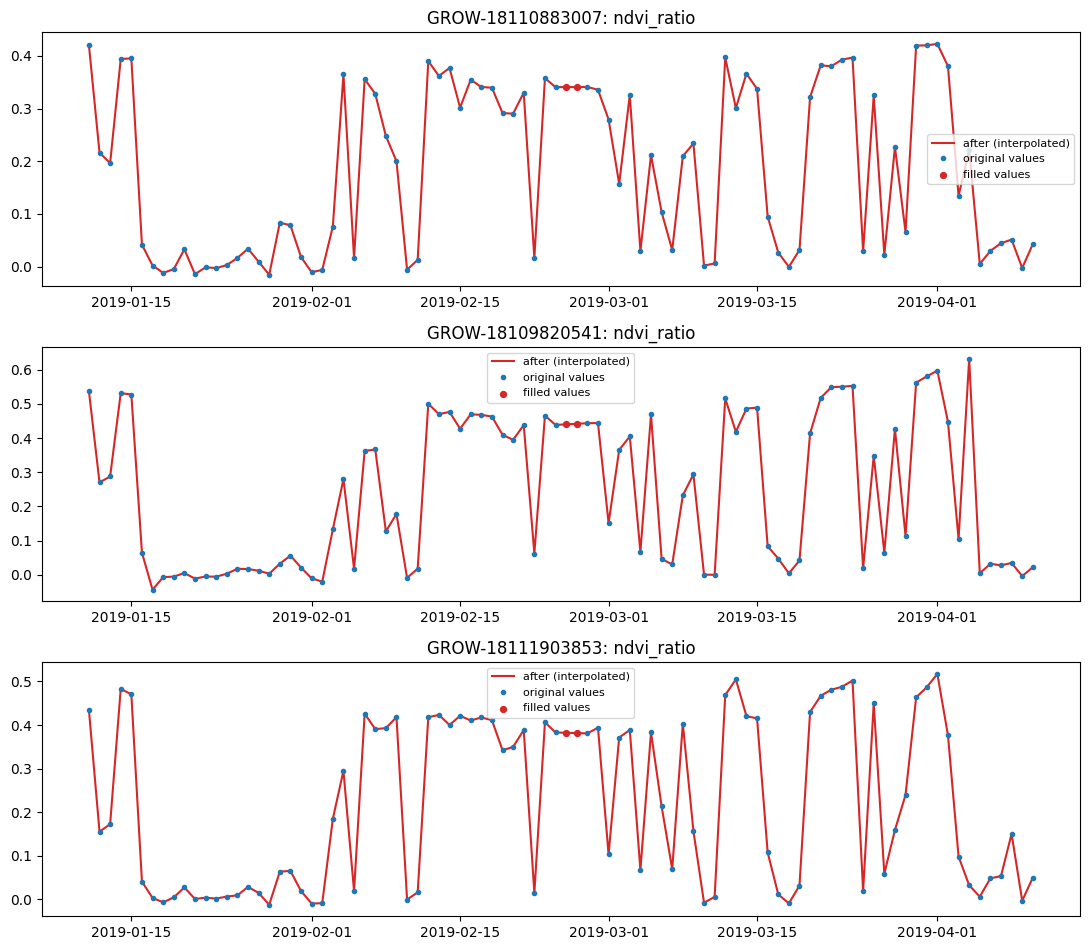

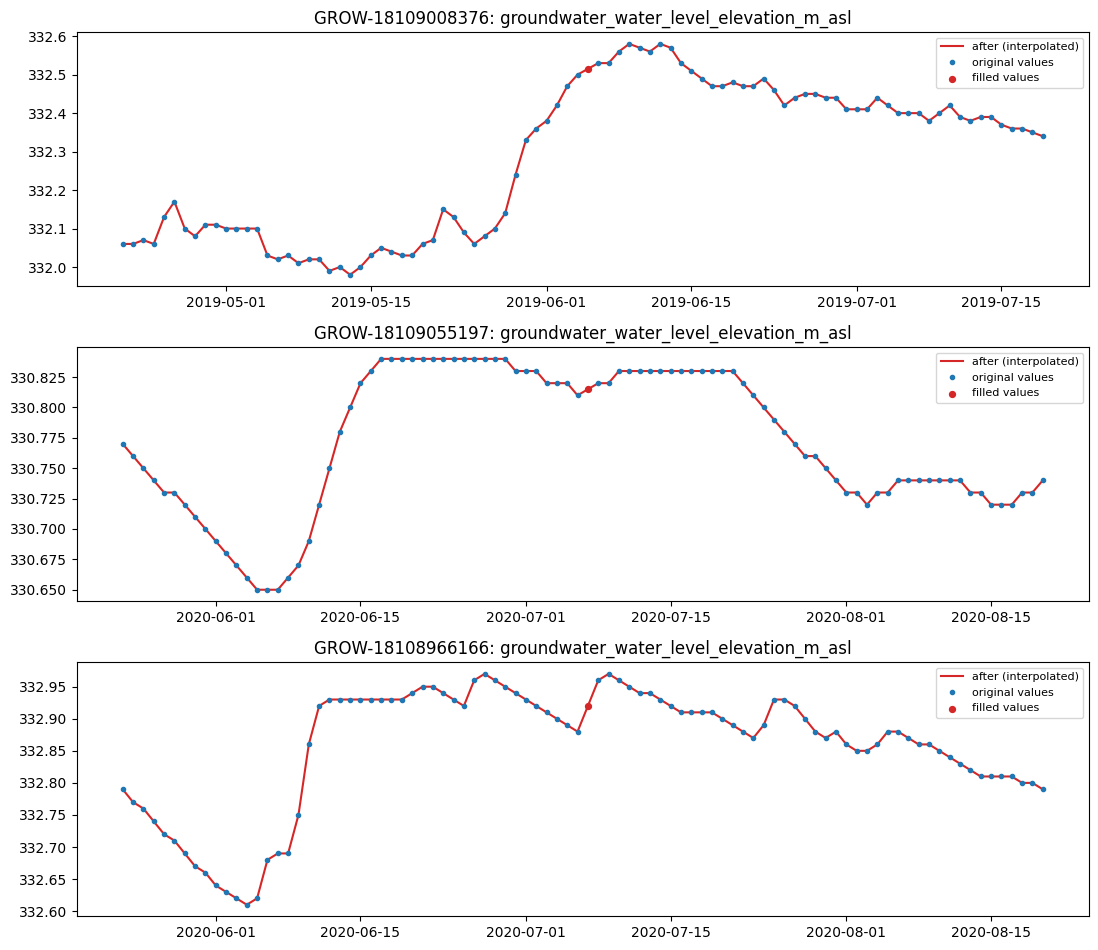

In [ ]:
# Visualize interpolation: before vs after

def plot_interp(col, n_wells=3, window=45, seed=0):
  # Select wells that had gaps in this column
  gappy = df_before.loc[df_before[col].isna(), "GROW_ID"].unique()
  wells = np.random.default_rng(seed).choice(gappy, size=min(n_wells, len(gappy)), replace=False)

  fig, axes = plt.subplots(len(wells), 1, figsize=(11, 3.2 * len(wells)))
  axes = np.atleast_1d(axes)
  for ax, w in zip(axes, wells):
    b = df_before[df_before.GROW_ID == w].reset_index(drop=True)
    a = df_daily[df_daily.GROW_ID == w].reset_index(drop=True)

    # Zoom in around the first gap
    i = b[col].isna().idxmax()
    lo, hi = max(i - window, 0), min(i + window, len(b))
    b, a = b.iloc[lo:hi], a.iloc[lo:hi]
    filled = b[col].isna()

    # Plot the graphs
    ax.plot(a["date"], a[col], color="tab:red", lw=1.5, label="after (interpolated)")
    ax.plot(b["date"], b[col], color="tab:blue", marker="o", ms=3, lw=0, label="original values")
    ax.scatter(a.loc[filled, "date"], a.loc[filled, col], color="tab:red", s=18, zorder=3, label="filled values")
    ax.set_title(f"{w}: {col}")
    ax.legend(loc="best", fontsize=8)
  plt.tight_layout()
  plt.show()

for c in cols_to_interp:
  plot_interp(c)
  print("\n")

In [ ]:
# TOY DATASET EXPERIMENT 1 - [Hafsa]
# Creating a small, fictional groundwater time series.

toy_data = {
    "date": pd.date_range(
        start="2026-01-01",
        periods=15,
        freq="D"
    ),
    "groundwater_level": [
        12.5, 12.4, 12.3, 12.2, np.nan,
        12.0, 11.9, 12.1, 12.0, 11.8,
        np.nan, 11.7, 11.6, 11.8, 11.5
    ]
}

df_toy = pd.DataFrame(toy_data)

print("Toy Dataset Shape:", df_toy.shape)
print("\nFirst Five Rows:")
display(df_toy.head())

print("\nMissing Values:")
print(df_toy.isna().sum())

Toy Dataset Shape: (15, 2)

First Five Rows:


,date,groundwater_level
0,2026-01-01,12.5
1,2026-01-02,12.4
2,2026-01-03,12.3
3,2026-01-04,12.2
4,2026-01-05,NaN



Missing Values:
date                 0
groundwater_level    2
dtype: int64


In [ ]:
# TOY DATASET EXPERIMENT 2 - [Hafsa]
# Filling missing groundwater measurements using linear interpolation.

df_toy["groundwater_level_filled"] = (
    df_toy["groundwater_level"].interpolate(method="linear")
)

print("Original vs. Interpolated Groundwater Levels:")

display(df_toy)

print("\nMissing Values Before Interpolation:")
print(df_toy["groundwater_level"].isna().sum())

print("\nMissing Values After Interpolation:")
print(df_toy["groundwater_level_filled"].isna().sum())

Original vs. Interpolated Groundwater Levels:


,date,groundwater_level,groundwater_level_filled
0,2026-01-01,12.5,12.50
1,2026-01-02,12.4,12.40
2,2026-01-03,12.3,12.30
3,2026-01-04,12.2,12.20
4,2026-01-05,NaN,12.10
5,2026-01-06,12.0,12.00
6,2026-01-07,11.9,11.90
7,2026-01-08,12.1,12.10
8,2026-01-09,12.0,12.00
9,2026-01-10,11.8,11.80



Missing Values Before Interpolation:
2

Missing Values After Interpolation:
0


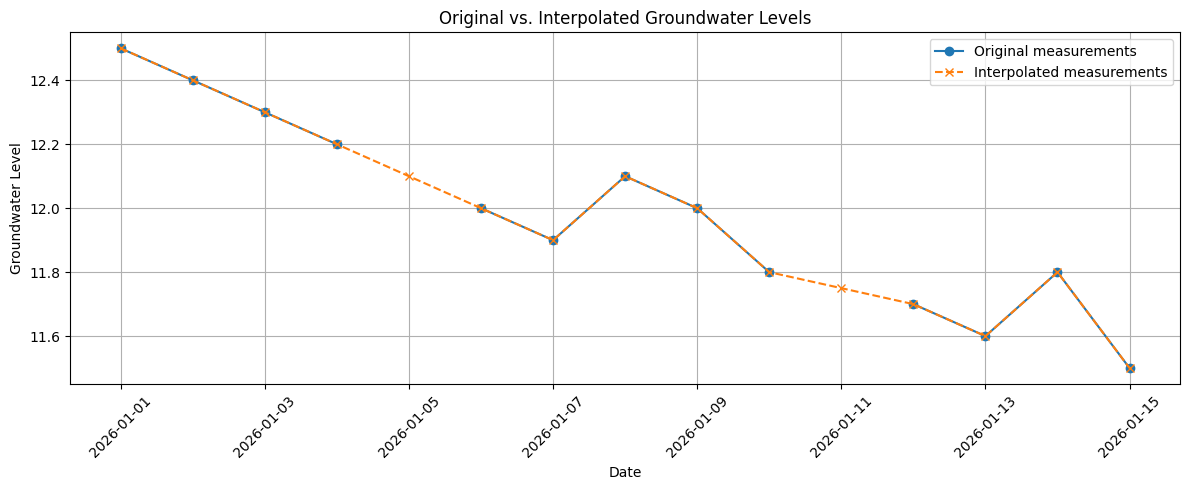

In [ ]:
# TOY DATASET EXPERIMENT 3 - [Hafsa]
# Visualizing original and interpolated groundwater measurements.

plt.figure(figsize=(12, 5))

# Plot the original measurements
plt.plot(
    df_toy["date"],
    df_toy["groundwater_level"],
    marker="o",
    label="Original measurements"
)

# Plot the interpolated measurements
plt.plot(
    df_toy["date"],
    df_toy["groundwater_level_filled"],
    marker="x",
    linestyle="--",
    label="Interpolated measurements"
)

plt.title("Original vs. Interpolated Groundwater Levels")
plt.xlabel("Date")
plt.ylabel("Groundwater Level")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# LSTM EXPERIMENT — [Hafsa]
# Step 1: Checking whether TensorFlow is available.

import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("LSTM is ready to use!")

TensorFlow version: 2.21.0
LSTM is ready to use!


Dataset shape: (365, 2)

First five observations:


,date,groundwater_level
0,2024-01-01,12.039737
1,2024-01-02,11.996546
2,2024-01-03,12.067026
3,2024-01-04,12.144652
4,2024-01-05,12.011669


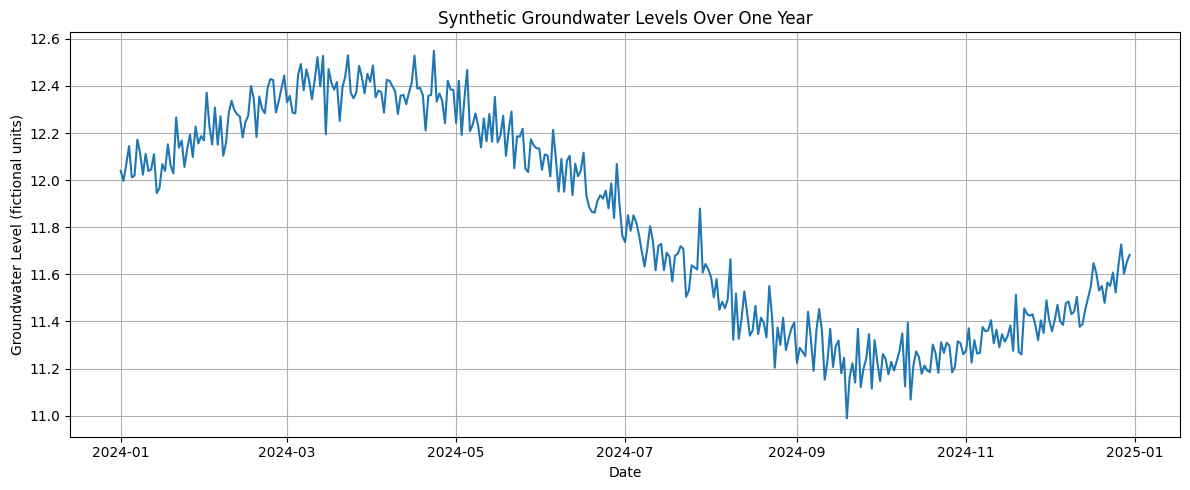

In [ ]:
# LSTM EXPERIMENT — [Hafsa]
# Step 2: Generating synthetic groundwater measurements.

# Make the experiment reproducible
np.random.seed(42)

# Generate 365 days of dates
dates = pd.date_range(
    start="2024-01-01",
    periods=365,
    freq="D"
)

# Create fictional groundwater measurements
days = np.arange(365)

groundwater_levels = (
    12
    - 0.001 * days
    + 0.5 * np.sin(2 * np.pi * days / 365)
    + np.random.normal(0, 0.08, 365)
)

# Store the data in a separate DataFrame
df_lstm_toy = pd.DataFrame({
    "date": dates,
    "groundwater_level": groundwater_levels
})

# Inspect the dataset
print("Dataset shape:", df_lstm_toy.shape)
print("\nFirst five observations:")
display(df_lstm_toy.head())

# Visualize the synthetic time series
plt.figure(figsize=(12, 5))
plt.plot(
    df_lstm_toy["date"],
    df_lstm_toy["groundwater_level"]
)

plt.title("Synthetic Groundwater Levels Over One Year")
plt.xlabel("Date")
plt.ylabel("Groundwater Level (fictional units)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# LSTM EXPERIMENT — [Hafsa]
# Step 3: Preparing historical sequences for forecasting.

from sklearn.preprocessing import MinMaxScaler

# Use the groundwater measurements
values = df_lstm_toy["groundwater_level"].values.reshape(-1, 1)

# Reserve the final 20% of observations for testing
split_index = int(len(values) * 0.8)

# Fit the scaler using training data only to avoid data leakage
scaler = MinMaxScaler()
scaler.fit(values[:split_index])

# Scale the measurements
scaled_values = scaler.transform(values)

# Create sequences: previous 30 days -> next day's measurement
window_size = 30

X = []
y = []
target_indices = []

for i in range(window_size, len(scaled_values)):
    X.append(scaled_values[i - window_size:i, 0])
    y.append(scaled_values[i, 0])
    target_indices.append(i)

X = np.array(X)
y = np.array(y)
target_indices = np.array(target_indices)

# Split sequences chronologically by their target dates
train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train = X[train_mask]
X_test = X[test_mask]

y_train = y[train_mask]
y_test = y[test_mask]

# LSTMs expect input shaped as:
# (number of sequences, timesteps, number of features)
X_train = X_train.reshape(X_train.shape[0], window_size, 1)
X_test = X_test.reshape(X_test.shape[0], window_size, 1)

print("Training input shape:", X_train.shape)
print("Training target shape:", y_train.shape)
print("Testing input shape:", X_test.shape)
print("Testing target shape:", y_test.shape)
print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training input shape: (262, 30, 1)
Training target shape: (262,)
Testing input shape: (73, 30, 1)
Testing target shape: (73,)
Training examples: 262
Testing examples: 73


In [ ]:
# LSTM EXPERIMENT — [Hafsa]
# Step 4: Building and training the LSTM model.

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

# Build the model
lstm_model = Sequential([
    Input(shape=(window_size, 1)),
    LSTM(32),
    Dense(1)
])

# Configure training
lstm_model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

# Stop early if validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Display the model architecture
lstm_model.summary()

# Train the model
history = lstm_model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=16,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1
)

print("\nLSTM training complete!")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - loss: 0.2742 - val_loss: 0.0056
Epoch 2/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0423 - val_loss: 0.0334
Epoch 3/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0059 - val_loss: 0.0128
Epoch 4/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0136 - val_loss: 0.0153
Epoch 5/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0075 - val_loss: 0.0108
Epoch 6/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0074 - val_loss: 0.0087

LSTM training complete!


LSTM Test Results
-----------------
Test observations: 73
Mean Absolute Error (MAE): 0.0666
Root Mean Squared Error (RMSE): 0.0854


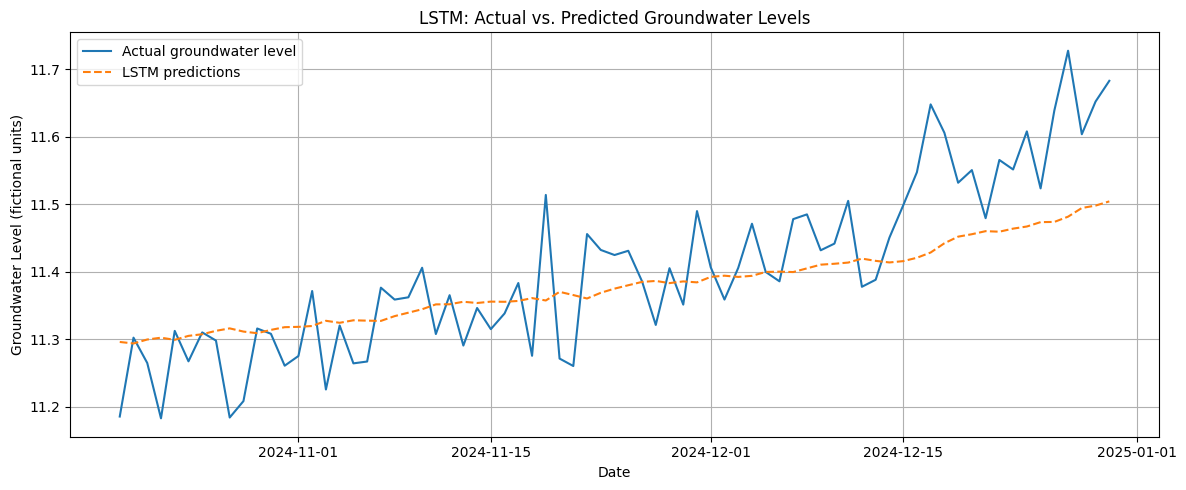

In [ ]:
# LSTM EXPERIMENT — [Hafsa]
# Step 5: Evaluating predictions on the held-out test data.

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Generate predictions
y_pred_scaled = lstm_model.predict(X_test, verbose=0)

# Convert predictions and actual targets back to the original scale
y_pred = scaler.inverse_transform(y_pred_scaled).flatten()
y_actual = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

# Calculate evaluation metrics
mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

print("LSTM Test Results")
print("-----------------")
print(f"Test observations: {len(y_actual)}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

# Plot actual versus predicted measurements
test_dates = df_lstm_toy["date"].iloc[target_indices[test_mask]]

plt.figure(figsize=(12, 5))

plt.plot(
    test_dates,
    y_actual,
    label="Actual groundwater level"
)

plt.plot(
    test_dates,
    y_pred,
    label="LSTM predictions",
    linestyle="--"
)

plt.title("LSTM: Actual vs. Predicted Groundwater Levels")
plt.xlabel("Date")
plt.ylabel("Groundwater Level (fictional units)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# ACTUAL GROUNDWATER LSTM TEST — [Hafsa]
# Step 1: Checking whether our original dataset is still available (because why not, lol).

if "df_daily" in globals():
    print("✅ Daily groundwater dataset is loaded!")
    print("Dataset shape:", df_daily.shape)

    print("\nAvailable columns:")
    print(df_daily.columns.tolist())

    print("\nFirst five observations:")
    display(df_daily.head())

else:
    print("❌ df_daily is not currently loaded.")
    print("We may need to reload the original dataset.")

✅ Daily groundwater dataset is loaded!
Dataset shape: (96778, 60)

Available columns:
['GROW_ID', 'interval', 'date', 'year', 'month', 'outliers_change_points', 'plateaus', 'groundwater_water_level_elevation_m_asl', 'precipitation_mswep_mm_year-1', 'precipitation_gpcc_mm_year-1', 'potential_evapotranspiration_era5_mm_year-1', 'potential_evapotranspiration_gleam_mm_year-1', 'actual_evapotranspiration_mm_year-1', 'interception_mm_year-1', 'air_temperature_°C', 'snow_depth_m', 'days_with_snow_cover_days_year-1', 'ndvi_ratio', 'lai_low_vegetation_ratio', 'lai_high_vegetation_ratio', 'withdrawal_industrial_m3_year-1', 'withdrawal_domestic_m3_year-1', 'urban_area_fraction', 'pastures_fraction', 'cropland_rainfed_fraction', 'forests_natural_vegetation_fraction', 'original_ID_groundwater', 'name', 'feature_type', 'purpose', 'latitude', 'longitude', 'country', 'organisation', 'license', 'starting_date', 'ending_date', 'length_years', 'autocorrelation', 'gap_fraction', 'trend_direction', 'trend_

,GROW_ID,interval,date,year,month,outliers_change_points,plateaus,groundwater_water_level_elevation_m_asl,precipitation_mswep_mm_year-1,precipitation_gpcc_mm_year-1,potential_evapotranspiration_era5_mm_year-1,potential_evapotranspiration_gleam_mm_year-1,actual_evapotranspiration_mm_year-1,interception_mm_year-1,air_temperature_°C,snow_depth_m,days_with_snow_cover_days_year-1,ndvi_ratio,lai_low_vegetation_ratio,lai_high_vegetation_ratio,withdrawal_industrial_m3_year-1,withdrawal_domestic_m3_year-1,urban_area_fraction,pastures_fraction,cropland_rainfed_fraction,forests_natural_vegetation_fraction,original_ID_groundwater,name,feature_type,purpose,latitude,longitude,country,organisation,license,starting_date,ending_date,length_years,autocorrelation,gap_fraction,trend_direction,trend_slope_m_year-1,reference_point,groundwater_mean_m,groundwater_median_m,koeppen_geiger_class,hydrobelt_class,ground_elevation_merit_m_asl,topographic_slope_degree,aquifer_type_class,permeability_0-100_m_m-2,total_porosity_0-100_m_fraction,soil_texture_0-30_cm_class,soil_texture_30-200_cm_class,soil_saturated_conductivity_0-30_cm_cm_d-1,soil_saturated_conductivity_30-200_cm_cm_d-1,distance_perennial_streams_m,drainage_density_m-1,main_landuse_class,distance_to_cluster_center_km
0,GROW-18108201772,d,2019-01-01,2019,2019-01,False,0,304.83,45.625,821.04,109.837026,98.319356,87.170150,28.274261,1.86523,0.007568,82.0,0.3128,2.940338,1.082947,81079016.0,17460536.0,0.028556,0.09373,0.051826,0.825888,1173,Mengeš (Mp-0275),Water well,Observation / monitoring,46.180855,14.581305,SVN,"Slovenia - MINISTRY OF THE ENVIRONMENT, CLIMATE AND ENERGY",Attribution 4.0 International (CC BY 4.0),2004-01-01,2023-12-31,20,True,0.000137,decreasing,-0.109268,Water level elevation a.m.s.l.,305.884637,305.38,Cfb,Mid-latitude,332.2,0.75,karst,3.019952e-11,0.22,Fine,Medium,5.8697,3.4658,4100.0,0.00031,forests_and_natural_vegetation,17.231858
1,GROW-18108201772,d,2019-01-02,2019,2019-01,False,0,304.79,0.000,821.04,224.211817,102.139899,89.009648,0.000000,0.65912,0.007812,82.0,0.1503,2.940125,1.078125,81079016.0,17460536.0,0.028556,0.09373,0.051826,0.825888,1173,Mengeš (Mp-0275),Water well,Observation / monitoring,46.180855,14.581305,SVN,"Slovenia - MINISTRY OF THE ENVIRONMENT, CLIMATE AND ENERGY",Attribution 4.0 International (CC BY 4.0),2004-01-01,2023-12-31,20,True,0.000137,decreasing,-0.109268,Water level elevation a.m.s.l.,305.884637,305.38,Cfb,Mid-latitude,332.2,0.75,karst,3.019952e-11,0.22,Fine,Medium,5.8697,3.4658,4100.0,0.00031,forests_and_natural_vegetation,17.231858
2,GROW-18108201772,d,2019-01-03,2019,2019-01,False,0,304.73,0.000,821.04,437.022274,580.862387,454.509862,0.000000,-0.86993,0.007324,82.0,0.4445,2.939972,1.073334,81079016.0,17460536.0,0.028556,0.09373,0.051826,0.825888,1173,Mengeš (Mp-0275),Water well,Observation / monitoring,46.180855,14.581305,SVN,"Slovenia - MINISTRY OF THE ENVIRONMENT, CLIMATE AND ENERGY",Attribution 4.0 International (CC BY 4.0),2004-01-01,2023-12-31,20,True,0.000137,decreasing,-0.109268,Water level elevation a.m.s.l.,305.884637,305.38,Cfb,Mid-latitude,332.2,0.75,karst,3.019952e-11,0.22,Fine,Medium,5.8697,3.4658,4100.0,0.00031,forests_and_natural_vegetation,17.231858
3,GROW-18108201772,d,2019-01-04,2019,2019-01,False,0,304.68,0.000,821.04,370.233991,523.731382,416.227750,0.000000,-1.03696,0.008057,82.0,0.4081,2.939758,1.068573,81079016.0,17460536.0,0.028556,0.09373,0.051826,0.825888,1173,Mengeš (Mp-0275),Water well,Observation / monitoring,46.180855,14.581305,SVN,"Slovenia - MINISTRY OF THE ENVIRONMENT, CLIMATE AND ENERGY",Attribution 4.0 International (CC BY 4.0),2004-01-01,2023-12-31,20,True,0.000137,decreasing,-0.109268,Water level elevation a.m.s.l.,305.884637,305.38,Cfb,Mid-latitude,332.2,0.75,karst,3.019952e-11,0.22,Fine,Medium,5.8697,3.4658,4100.0,0.00031,forests_and_natural_vegetation,17.231858
4,GROW-18108201772,d,2019-01-05,2019,2019-01,False,0,304.64,0.000,821.04,211.796455,107.252337,92.038305,0.000000,-0.48114,0.008789,82.0,0.0

In [ ]:
# ACTUAL GROUNDWATER LSTM TEST — [Hafsa]
# Step 2: Finding wells suitable for forecasting.

target_col = "groundwater_water_level_elevation_m_asl"

# Summarize the available observations for each well
well_summary = (
    df_daily.groupby("GROW_ID")
    .agg(
        total_observations=(target_col, "size"),
        valid_measurements=(target_col, "count"),
        first_date=("date", "min"),
        last_date=("date", "max")
    )
)

well_summary["missing_measurements"] = (
    well_summary["total_observations"]
    - well_summary["valid_measurements"]
)

well_summary["missing_pct"] = (
    well_summary["missing_measurements"]
    / well_summary["total_observations"]
    * 100
).round(2)

# Show wells with at least 300 valid measurements
# and no more than 5% missing groundwater measurements
suitable_wells = well_summary[
    (well_summary["valid_measurements"] >= 300)
    & (well_summary["missing_pct"] <= 5)
].sort_values(
    "valid_measurements",
    ascending=False
)

print("Total unique wells:", df_daily["GROW_ID"].nunique())
print("Wells meeting our initial criteria:", len(suitable_wells))

print("\nTop 10 candidate wells:")
display(suitable_wells.head(10))

Total unique wells: 53
Wells meeting our initial criteria: 53

Top 10 candidate wells:


,total_observations,valid_measurements,first_date,last_date,missing_measurements,missing_pct
GROW_ID,,,,,,
GROW-18108201772,1826,1826,2019-01-01,2023-12-31,0,0.0
GROW-18108286252,1826,1826,2019-01-01,2023-12-31,0,0.0
GROW-18108328402,1826,1826,2019-01-01,2023-12-31,0,0.0
GROW-18108370783,1826,1826,2019-01-01,2023-12-31,0,0.0
GROW-18108413683,1826,1826,2019-01-01,2023-12-31,0,0.0
GROW-18108456083,1826,1826,2019-01-01,2023-12-31,0,0.0
GROW-18108540984,1826,1826,2019-01-01,2023-12-31,0,0.0
GROW-18108795755,1826,1826,2019-01-01,2023-12-31,0,0.0
GROW-18108838445,1826,1826,2019-01-01,2023-12-31,0,0.0


Selected well: GROW-18108201772
Number of observations: 1826
First observation: 2019-01-01 00:00:00
Last observation: 2023-12-31 00:00:00
Missing groundwater measurements: 0

First five observations:


,date,groundwater_water_level_elevation_m_asl
0,2019-01-01,304.83
1,2019-01-02,304.79
2,2019-01-03,304.73
3,2019-01-04,304.68
4,2019-01-05,304.64


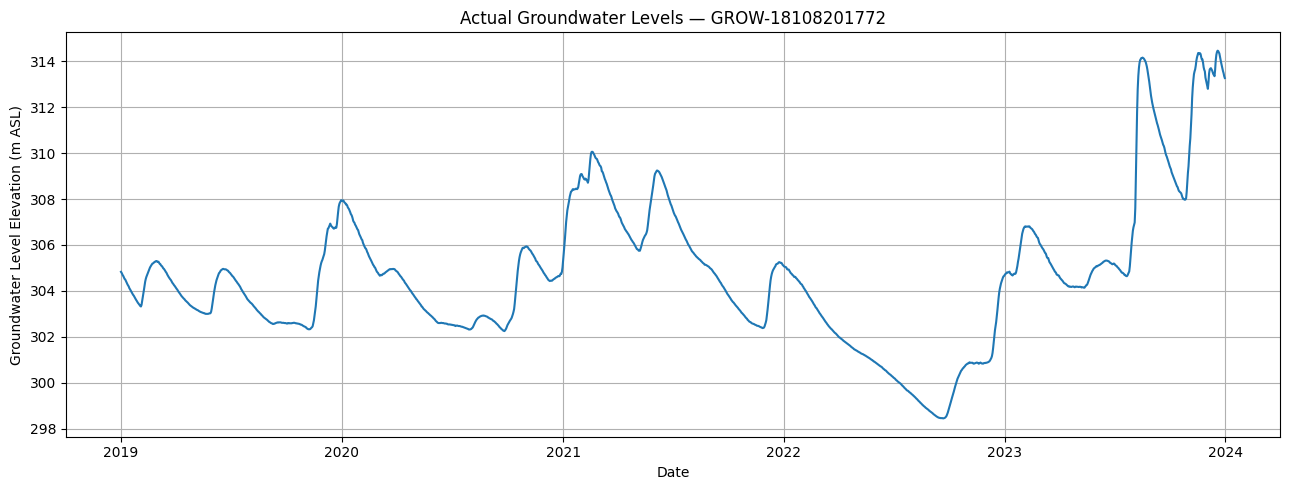

In [ ]:
# ACTUAL GROUNDWATER LSTM TEST — [Hafsa]
# Step 3: Inspecting and visualizing one of the groundwater wells.

# Select one well from the candidate list
selected_well = "GROW-18108201772"

# Create a separate DataFrame for this experiment
df_well = df_daily[
    df_daily["GROW_ID"] == selected_well
].copy()

# Prepare the time series
df_well["date"] = pd.to_datetime(df_well["date"])

df_well = (
    df_well.sort_values("date")
    .reset_index(drop=True)
)

# Inspect the data
print("Selected well:", selected_well)
print("Number of observations:", len(df_well))
print("First observation:", df_well["date"].min())
print("Last observation:", df_well["date"].max())

print(
    "Missing groundwater measurements:",
    df_well["groundwater_water_level_elevation_m_asl"].isna().sum()
)

print("\nFirst five observations:")
display(
    df_well[
        ["date", "groundwater_water_level_elevation_m_asl"]
    ].head()
)

# Plot the actual groundwater measurements
plt.figure(figsize=(13, 5))

plt.plot(
    df_well["date"],
    df_well["groundwater_water_level_elevation_m_asl"]
)

plt.title(f"Actual Groundwater Levels — {selected_well}")
plt.xlabel("Date")
plt.ylabel("Groundwater Level Elevation (m ASL)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# ACTUAL GROUNDWATER LSTM TEST — [Hafsa]
# Step 4: Preparing sequences for seven-day-ahead forecasting.

# Extract the groundwater measurements
real_values = df_well[
    "groundwater_water_level_elevation_m_asl"
].to_numpy().reshape(-1, 1)

# Define the forecasting setup
window_size_real = 30
forecast_horizon = 7

# Reserve the final 20% of observations for testing
split_index_real = int(len(real_values) * 0.8)

# Fit the scaler on the training period only
real_scaler = MinMaxScaler()
real_scaler.fit(real_values[:split_index_real])

# Scale the full series using the training-fitted scaler
scaled_real_values = real_scaler.transform(real_values)

# Create input sequences and seven-day-ahead targets
X_real = []
y_real = []
target_indices_real = []

for i in range(
    window_size_real,
    len(scaled_real_values) - forecast_horizon + 1
):
    target_index = i + forecast_horizon - 1

    X_real.append(
        scaled_real_values[i - window_size_real:i, 0]
    )

    y_real.append(
        scaled_real_values[target_index, 0]
    )

    target_indices_real.append(target_index)

X_real = np.array(X_real)
y_real = np.array(y_real)
target_indices_real = np.array(target_indices_real)

# Split by target date to preserve chronological order
train_mask_real = target_indices_real < split_index_real
test_mask_real = target_indices_real >= split_index_real

X_train_real = X_real[train_mask_real]
X_test_real = X_real[test_mask_real]

y_train_real = y_real[train_mask_real]
y_test_real = y_real[test_mask_real]

# Reshape for the LSTM:
# (number of sequences, timesteps, number of features)
X_train_real = X_train_real.reshape(
    X_train_real.shape[0], window_size_real, 1
)

X_test_real = X_test_real.reshape(
    X_test_real.shape[0], window_size_real, 1
)

print("Selected well:", selected_well)
print("Forecast horizon:", forecast_horizon, "days")
print("Historical input window:", window_size_real, "days")
print()
print("Training input shape:", X_train_real.shape)
print("Training target shape:", y_train_real.shape)
print("Testing input shape:", X_test_real.shape)
print("Testing target shape:", y_test_real.shape)
print()
print(
    "First test target date:",
    df_well["date"].iloc[target_indices_real[test_mask_real][0]]
)
print(
    "Last test target date:",
    df_well["date"].iloc[target_indices_real[test_mask_real][-1]]
)

Selected well: GROW-18108201772
Forecast horizon: 7 days
Historical input window: 30 days

Training input shape: (1424, 30, 1)
Training target shape: (1424,)
Testing input shape: (366, 30, 1)
Testing target shape: (366,)

First test target date: 2022-12-31 00:00:00
Last test target date: 2023-12-31 00:00:00


In [ ]:
# ACTUAL GROUNDWATER LSTM TEST — [Hafsa]
# Step 5: Building and training a seven-day-ahead forecasting model (please work, lol...).

# Build the LSTM model
real_lstm_model = Sequential([
    Input(shape=(window_size_real, 1)),
    LSTM(32),
    Dense(1)
])

# Configure training
real_lstm_model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

# Stop if validation loss stops improving
real_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Display model architecture
real_lstm_model.summary()

# Train the model
real_history = real_lstm_model.fit(
    X_train_real,
    y_train_real,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    shuffle=False,
    callbacks=[real_early_stopping],
    verbose=1
)

print("\nReal-data LSTM training complete!")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0771 - val_loss: 0.0141
Epoch 2/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0083 - val_loss: 0.0173
Epoch 3/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0070 - val_loss: 0.0141
Epoch 4/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0061 - val_loss: 0.0114
Epoch 5/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0054 - val_loss: 0.0097
Epoch 6/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0050 - val_loss: 0.0087
Epoch 7/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0048 - val_loss: 0.0082
Epoch 8/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0046 - val_loss: 0.0079
Epoch 9/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0044 - val_loss: 0.0077
Epoch 10/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0043 - val_loss: 0.0076
Epoch 11/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0042 - val_loss: 0.0074
Epoch 12/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0

REAL GROUNDWATER LSTM — TEST RESULTS
------------------------------------
Selected well: GROW-18108201772
Forecast horizon: 7 days
Test observations: 366
MAE: 0.8170 meters
RMSE: 1.4499 meters


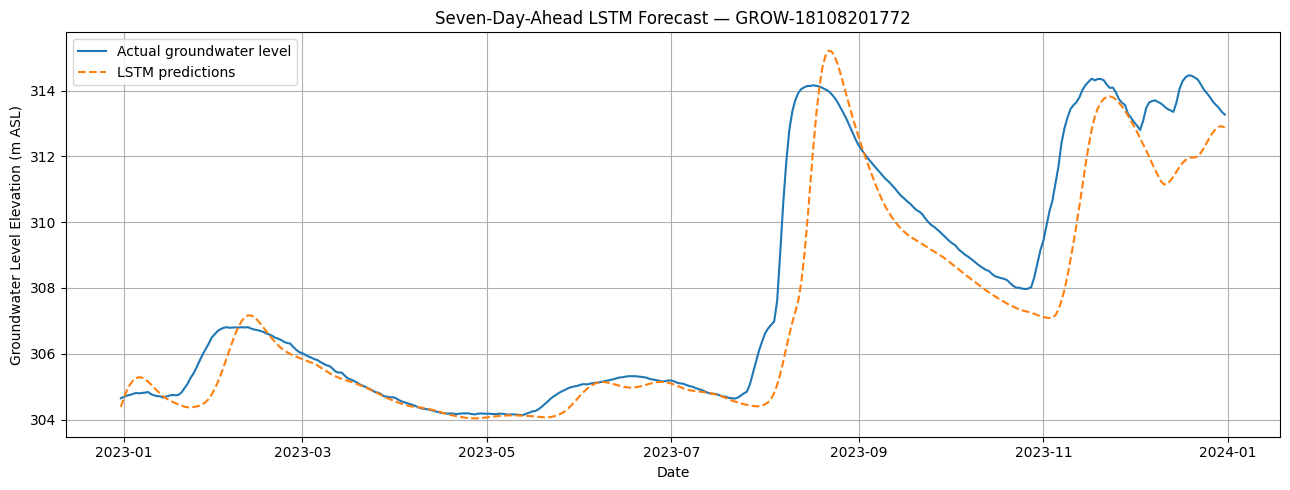

In [ ]:
# ACTUAL GROUNDWATER LSTM TEST — [Hafsa]
# Step 6: Evaluating the seven-day-ahead predictions (hoping I did it right, haha).

# Generate predictions for the held-out test sequences
y_pred_real_scaled = real_lstm_model.predict(
    X_test_real,
    verbose=0
)

# Convert predictions and actual values back to meters
y_pred_real = real_scaler.inverse_transform(
    y_pred_real_scaled
).flatten()

y_actual_real = real_scaler.inverse_transform(
    y_test_real.reshape(-1, 1)
).flatten()

# Calculate evaluation metrics
mae_real = mean_absolute_error(
    y_actual_real,
    y_pred_real
)

rmse_real = np.sqrt(
    mean_squared_error(
        y_actual_real,
        y_pred_real
    )
)

print("REAL GROUNDWATER LSTM — TEST RESULTS")
print("------------------------------------")
print("Selected well:", selected_well)
print("Forecast horizon:", forecast_horizon, "days")
print("Test observations:", len(y_actual_real))
print(f"MAE: {mae_real:.4f} meters")
print(f"RMSE: {rmse_real:.4f} meters")

# Get the dates corresponding to the test targets
test_dates_real = df_well["date"].iloc[
    target_indices_real[test_mask_real]
]

# Plot actual measurements against predictions
plt.figure(figsize=(13, 5))

plt.plot(
    test_dates_real,
    y_actual_real,
    label="Actual groundwater level"
)

plt.plot(
    test_dates_real,
    y_pred_real,
    label="LSTM predictions",
    linestyle="--"
)

plt.title(
    f"Seven-Day-Ahead LSTM Forecast — {selected_well}"
)

plt.xlabel("Date")
plt.ylabel("Groundwater Level Elevation (m ASL)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# FINAL EXPERIMENT (for my sanity because I doubt myself too much and wanna practice more, heh) — [Hafsa]
# Comparing LSTM with a Persistence Baseline.

# The baseline predicts that the level 7 days ahead will equal the most recent measurement in the 30-day input window.
baseline_pred_scaled = X_test_real[:, -1, 0].reshape(-1, 1)

# Convert baseline predictions to meters
baseline_pred = real_scaler.inverse_transform(
    baseline_pred_scaled
).flatten()

# Calculate baseline metrics
baseline_mae = mean_absolute_error(
    y_actual_real, baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_actual_real, baseline_pred)
)

# Compare both approaches
comparison = pd.DataFrame({
    "Model": ["LSTM", "Persistence Baseline"],
    "MAE (meters)": [mae_real, baseline_mae],
    "RMSE (meters)": [rmse_real, baseline_rmse]
})

print("FINAL MODEL COMPARISON")
display(comparison.round(4))

if mae_real < baseline_mae:
    print("The LSTM has lower MAE than the baseline.")
else:
    print("The baseline has equal or lower MAE than the LSTM.")

if rmse_real < baseline_rmse:
    print("The LSTM has lower RMSE than the baseline.")
else:
    print("The baseline has equal or lower RMSE than the LSTM.")

FINAL MODEL COMPARISON


,Model,MAE (meters),RMSE (meters)
0,LSTM,0.817,1.4499
1,Persistence Baseline,0.618,1.1277


The baseline has equal or lower MAE than the LSTM.
The baseline has equal or lower RMSE than the LSTM.
